# Portfolio Manager Workbench — Meridian Target Retirement Series
Run the agent pipeline, inspect each vintage's proposal against its glide path, understand *why* the CIO agent proposed it, and try what-ifs.

> Runs on **synthetic data** unless a real data source is enabled in `config/data_sources.yaml`. Outputs are hypothetical.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from meridian.pipelines.target_date import run
from meridian.policy import load_policy, load_universe
from meridian import entities

## 1. Run the pipeline
The run writes a board memo, a compliance report, results and a hash-chained ledger to `runs/<run_id>/`.

In [2]:
res = run(as_of='2026-10-31')
print(res.run_id, '| ledger:', res.ledger_ok)

run_tds_20261031_f3c759 | ledger: (True, 'verified 118 records; head ccb82fbb5a8e')


## 2. Series summary

In [3]:
summary = pd.DataFrame({v: {'yrs_to_target': d['years_to_target'], 'equity_glide': d['equity_neutral'], 'equity_proposed': d['equity_final'],
    'tilt_pp': (d['equity_final']-d['equity_neutral'])*100, 'exp_return': d['exp_ret'], 'vol': d['vol'], 'te': d['te'],
    'ensemble': d['ensemble'], 'compliance': d['compliance_summary']['overall']} for v, d in res.vintages.items()}).T
summary

,yrs_to_target,equity_glide,equity_proposed,tilt_pp,exp_return,vol,te,ensemble,compliance
2030,3.1700,0.4807,0.4659,-1.4827,0.0557,0.0800,0.0052,inverse_tracking_error,PASS (attestations pending)
2035,8.1700,0.5734,0.5608,-1.2625,0.0585,0.0936,0.0057,inverse_tracking_error,PASS (attestations pending)
2040,13.1700,0.6734,0.6634,-0.9997,0.0616,0.1096,0.0061,inverse_tracking_error,PASS (attestations pending)
2045,18.1700,0.7480,0.7380,-1.0014,0.0637,0.1211,0.0064,inverse_tracking_error,PASS (attestations pending)
2050,23.1700,0.8080,0.7972,-1.0856,0.0653,0.1301,0.0065,inverse_tracking_error,PASS (attestations pending)
2055,28.1700,0.8363,0.8262,-1.0151,0.0660,0.1344,0.0066,inverse_tracking_error,PASS (attestations pending)
2060,33.1700,0.8463,0.8359,-1.0393,0.0663,0.1358,0.0067,inverse_tracking_error,PASS (attestations pending)
2065,38.1700,0.8563,0.8457,-1.0654,0.0665,0.1373,0.0069,inverse_tracking_error,PASS (attestations pending)
2070,43.1700,0.8600,0.8493,-1.0746,0.0666,0.1378,0.0069,inverse_tracking_error,PASS (attestations pending)


## 3. Glide path

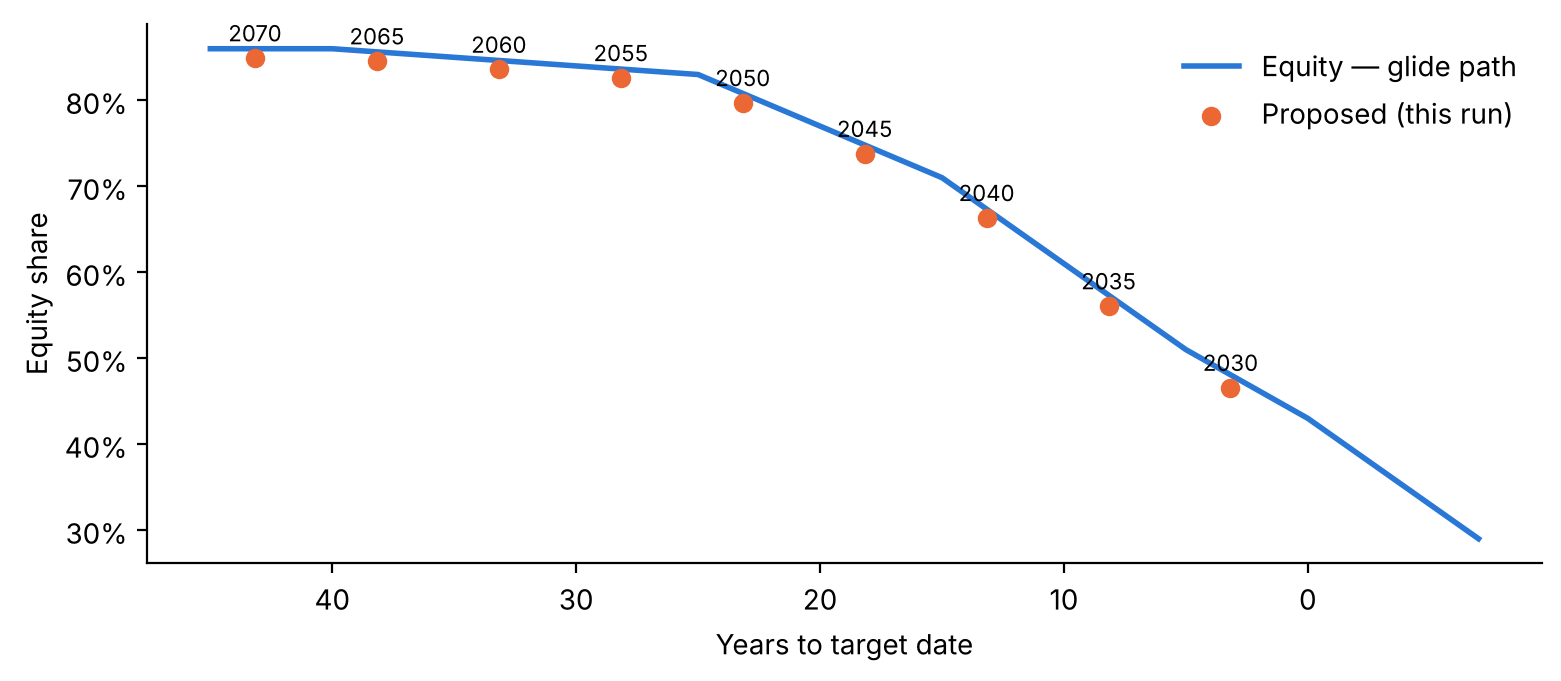

In [4]:
pol = load_policy(); eq = pol.group_mask('equity'); yrs = np.arange(45, -7.5, -0.5)
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(yrs, [eq @ pol.neutral_weights(y) for y in yrs], lw=2, color='#2a78d6', label='Equity — glide path')
for v, d in res.vintages.items():
    ax.scatter(d['years_to_target'], d['equity_final'], color='#eb6834', zorder=3)
    ax.annotate(str(v), (d['years_to_target'], d['equity_final']), textcoords='offset points', xytext=(0,6), ha='center', fontsize=8)
ax.invert_xaxis(); ax.set_xlabel('Years to target date'); ax.set_ylabel('Equity share'); ax.yaxis.set_major_formatter(lambda x,_: f'{x:.0%}')
ax.scatter([],[],color='#eb6834',label='Proposed (this run)'); ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False); plt.show()

## 4. Drill into one vintage

In [5]:
V = 2050
d = res.vintages[V]
pd.DataFrame({'glide_path': d['neutral'], 'proposed': d['final']}).assign(active_pp=lambda t: (t.proposed - t.glide_path)*100)

,glide_path,proposed,active_pp
us_large_cap,0.4490,0.4540,0.5000
us_small_mid_cap,0.0763,0.0648,-1.1500
intl_developed_eq,0.2245,0.2317,0.7200
emerging_eq,0.0582,0.0467,-1.1500
global_reits,0.0300,0.0126,-1.7400
commodities,0.0100,0.0126,0.2600
us_core_bond,0.0910,0.0989,0.7900
us_long_treasury,0.0218,0.0360,1.4200
us_tips_short,0.0037,0.0098,0.6100
us_high_yield,0.0118,0.0070,-0.4800


In [6]:
print('WHY:', d['rationale'])
print('\nWHAT WOULD MAKE THIS WRONG:'); [print(' -', c) for c in d['invalidation_conditions']]
pd.DataFrame(d['ranking'])

WHY: Inverse-tracking-error ensemble (paper §4.4): weights methods closer to the consensus more heavily, keeps every method's information, and stays well inside the TE budget; individual optimizers are sensitive to CMA error in a late-cycle regime.

WHAT WOULD MAKE THIS WRONG:
 - Macro regime shifts away from late-cycle
 - Any CMA moves outside its method range on the next run
 - Equity drawdown > 15% from run date (off-cycle review trigger)
 - Tracking error vs. glide path rises above 1.0% (warning threshold)


,method,composite,votes
0,risk_budget_tilt,0.7490,8
1,min_variance_tilt,0.7150,11
2,max_sharpe_tilt,0.7070,8
3,black_litterman_tilt,0.6560,7
4,max_diversification_tilt,0.5790,5
5,glide_path_neutral,0.5300,-2
6,adversarial_diversifier,0.1590,-9


## 5. What-if: a different operating entity
Selecting a different set of entity types switches compliance rules, approvers and retention — no code changes.

In [7]:
alt = run(as_of='2026-10-31', selected_entities=['broker_dealer', 'sec_ria'])
print('approvers 2050 now:', alt.vintages[2050]['approvers'])
pd.Series({r['rule_id']: r['status'] for r in alt.vintages[2050]['compliance']}).value_counts()

approvers 2050 now: ['portfolio_manager', 'registered_principal', 'risk']


PASS      13
OFF        4
ATTEST     1
Name: count, dtype: int64

## 6. Approve (writes an immutable ledger record)
Uncomment to record your decision. A reason is required; FAILs block approval.

In [8]:
from meridian.approvals import record_decision
# record_decision(res.out_dir, 2050, 'portfolio_manager', 'Dev', 'approve', 'Modest late-cycle de-risking; within all limits.')